Import libraries

In [1]:
import os
import sys
from pathlib import Path

# Find project root
current_dir = Path.cwd()

possible_roots = [
    current_dir,
    current_dir.parent,
]

PROJECT_ROOT = None

for path in possible_roots:
    if (path / "src" / "data" / "dataset.py").exists():
        PROJECT_ROOT = path
        break

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Cannot find project root containing src/data/dataset.py"
    )

# Add project root to Python path
sys.path.insert(0, str(PROJECT_ROOT))

os.chdir(PROJECT_ROOT)

print("Project root:", PROJECT_ROOT)
print("Python path updated successfully.")

Project root: d:\Industrial Surface Defect Detection and Classification Using CNN,Transfer Learning and Tensorflow
Python path updated successfully.


In [2]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from pathlib import Path
from src.data.dataset import get_dataset_splits

print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)

TensorFlow: 2.10.0
NumPy: 1.26.4


Configuration

In [3]:
DATASET_PATH = "data/NEU-DET"

IMAGE_SIZE = 224
CHANNELS = 3

CLASS_NAMES = [
    "crazing",
    "inclusion",
    "patches",
    "pitted_surface",
    "rolled-in_scale",
    "scratches"
]

print("Image size:", IMAGE_SIZE)
print("Number of classes:", len(CLASS_NAMES))

Image size: 224
Number of classes: 6


Load dataset

In [4]:
train, val, test = get_dataset_splits(DATASET_PATH)

print("Training images:", len(train))
print("Validation images:", len(val))
print("Testing images:", len(test))

Training images: 1151
Validation images: 288
Testing images: 360


Create preprocessing function

In [5]:
def preprocess_image(image_path, image_size=224):

    image = cv2.imread(str(image_path))

    if image is None:
        raise FileNotFoundError(
            f"Unable to load image: {image_path}"
        )

    image = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB
    )

    original_height, original_width = image.shape[:2]

    image = cv2.resize(
        image,
        (image_size, image_size)
    )

    image = image.astype(np.float32)

    # MobileNetV2 preprocessing
    image = tf.keras.applications.mobilenet_v2.preprocess_input(
        image
    )

    return image, original_width, original_height

Bounding-box preprocessing

In [6]:
def preprocess_boxes(boxes):

    boxes = np.asarray(boxes, dtype=np.float32).copy()

    if boxes.size == 0:
        return boxes.reshape(0, 4)

    # Expected format:
    # [xmin, ymin, xmax, ymax]

    if np.any(boxes < 0) or np.any(boxes > 1):
        raise ValueError(
            "Bounding boxes must be normalized between 0 and 1."
        )

    return boxes

Preprocess one training sample

In [7]:
sample = train[0]

image, original_width, original_height = preprocess_image(
    sample["image"],
    IMAGE_SIZE
)

boxes = preprocess_boxes(sample["boxes"])
labels = np.asarray(sample["labels"])

print("Image shape:", image.shape)
print("Image dtype:", image.dtype)

print("Original width:", original_width)
print("Original height:", original_height)

print("Bounding boxes:", boxes)
print("Labels:", labels)

print("Pixel minimum:", image.min())
print("Pixel maximum:", image.max())

Image shape: (224, 224, 3)
Image dtype: float32
Original width: 200
Original height: 200
Bounding boxes: [[0.425 0.185 0.685 0.515]]
Labels: [4]
Pixel minimum: -0.3490196
Pixel maximum: 0.38823533


Visualize preprocessed image

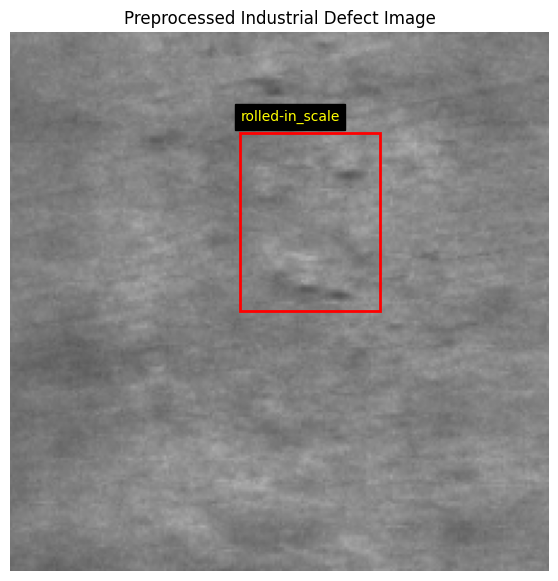

In [8]:
display_image = (image + 1.0) / 2.0

plt.figure(figsize=(7, 7))

plt.imshow(display_image)

for box, label in zip(boxes, labels):

    xmin, ymin, xmax, ymax = box

    x1 = xmin * IMAGE_SIZE
    y1 = ymin * IMAGE_SIZE
    x2 = xmax * IMAGE_SIZE
    y2 = ymax * IMAGE_SIZE

    rectangle = plt.Rectangle(
        (x1, y1),
        x2 - x1,
        y2 - y1,
        fill=False,
        edgecolor="red",
        linewidth=2
    )

    plt.gca().add_patch(rectangle)

    plt.text(
        x1,
        max(y1 - 5, 0),
        CLASS_NAMES[int(label)],
        color="yellow",
        backgroundcolor="black"
    )

plt.title("Preprocessed Industrial Defect Image")
plt.axis("off")
plt.show()

Data augmentation

In [9]:
def augment_image_and_boxes(image, boxes, horizontal=False,
                            vertical=False, rotate_k=0):

    image = image.copy()
    boxes = boxes.copy()

    if horizontal:
        image = np.flip(image, axis=1)

        xmin = boxes[:, 0].copy()
        xmax = boxes[:, 2].copy()

        boxes[:, 0] = 1.0 - xmax
        boxes[:, 2] = 1.0 - xmin

    if vertical:
        image = np.flip(image, axis=0)

        ymin = boxes[:, 1].copy()
        ymax = boxes[:, 3].copy()

        boxes[:, 1] = 1.0 - ymax
        boxes[:, 3] = 1.0 - ymin

    rotate_k = rotate_k % 4

    for _ in range(rotate_k):
        image = np.rot90(image, k=1)

        xmin = boxes[:, 0].copy()
        ymin = boxes[:, 1].copy()
        xmax = boxes[:, 2].copy()
        ymax = boxes[:, 3].copy()

        boxes[:, 0] = ymin
        boxes[:, 1] = 1.0 - xmax
        boxes[:, 2] = ymax
        boxes[:, 3] = 1.0 - xmin

    return np.ascontiguousarray(image), boxes

Test augmentation

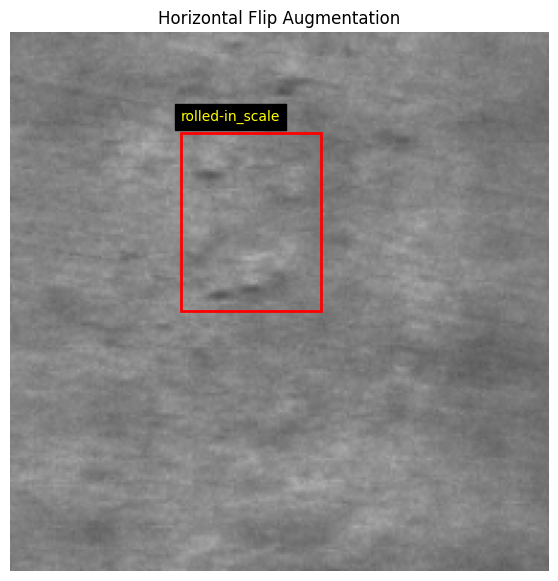

In [10]:
augmented_image, augmented_boxes = augment_image_and_boxes(
    image,
    boxes,
    horizontal=True,
    vertical=False,
    rotate_k=0
)

plt.figure(figsize=(7, 7))

plt.imshow((augmented_image + 1.0) / 2.0)

for box, label in zip(augmented_boxes, labels):

    xmin, ymin, xmax, ymax = box

    plt.gca().add_patch(
        plt.Rectangle(
            (xmin * IMAGE_SIZE, ymin * IMAGE_SIZE),
            (xmax - xmin) * IMAGE_SIZE,
            (ymax - ymin) * IMAGE_SIZE,
            fill=False,
            edgecolor="red",
            linewidth=2
        )
    )

    plt.text(
        xmin * IMAGE_SIZE,
        max(ymin * IMAGE_SIZE - 5, 0),
        CLASS_NAMES[int(label)],
        color="yellow",
        backgroundcolor="black"
    )

plt.title("Horizontal Flip Augmentation")
plt.axis("off")
plt.show()

Verify bounding-box validity

In [11]:
assert np.all(augmented_boxes >= 0)
assert np.all(augmented_boxes <= 1)

assert np.all(
    augmented_boxes[:, 0] < augmented_boxes[:, 2]
)

assert np.all(
    augmented_boxes[:, 1] < augmented_boxes[:, 3]
)

print("Image preprocessing: PASSED")
print("Bounding-box preprocessing: PASSED")
print("Augmentation verification: PASSED")

Image preprocessing: PASSED
Bounding-box preprocessing: PASSED
Augmentation verification: PASSED
